# Indian E-Commerce Sales Analytics
## 03 - Exploratory Data Analysis

In [1]:
# Import some libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import confidential_file as paths

### Goal
Find patterns in sales, customers, products, and order operations.

## 1. Load Data
Load the three cleaned CSV files. Update the file paths if needed.

In [2]:
customers = paths.customers
products = paths.products
sales = paths.sales

In [3]:
customers.head()

,Customer_ID,Customer_Name,Gender,Age,Age_Group,Date_of_Birth,Email,Phone,City,State,Pincode,Registration_Date,Customer_Tier,Total_Orders,Total_Spent
0,CUST00000001,Akash Agarwal,male,48,46-55,1977-01-13,akashagarwal@gmail.com,+91-9625152011,Patiala,Punjab,122521,2024-01-28,Gold,5,40098.48
1,CUST00000002,Farhan Rahman,male,73,65+,1952-01-20,farhanrahman@gmail.com,+91-8593009465,Durgapur,West Bengal,226518,2023-08-25,Platinum,8,63676.24
2,CUST00000003,Suresh Kumar,male,31,26-35,1994-01-09,sureshkumar755@gmail.com,+91-7935884774,Gurugram,Haryana,520400,2023-08-30,Silver,0,0.00
3,CUST00000004,Aditya Pandey,male,41,36-45,1984-01-12,adityapandey@outlook.com,+91-9015046072,Kolkata,West Bengal,735356,2024-03-11,Platinum,5,288324.84
4,CUST00000005,Hina Khan,female,53,46-55,1972-01-15,hinakhan433@gmail.com,+91-8813094271,Noida,UP,985141,2024-04-19,Platinum,4,69265.75


In [4]:
# How much sales value is recorded
print(f"Total Sales Value is: {sales["Total_Amount"].sum().round(2)}")

Total Sales Value is: 5930693254.3


## 2. Sales Analysis
Find total sales, order status counts, monthly sales, payment method usage, and average order value.

Questions:
- How much sales value is recorded?
- Which months perform best?
- Which order statuses are most common?
- Which payment methods are popular?

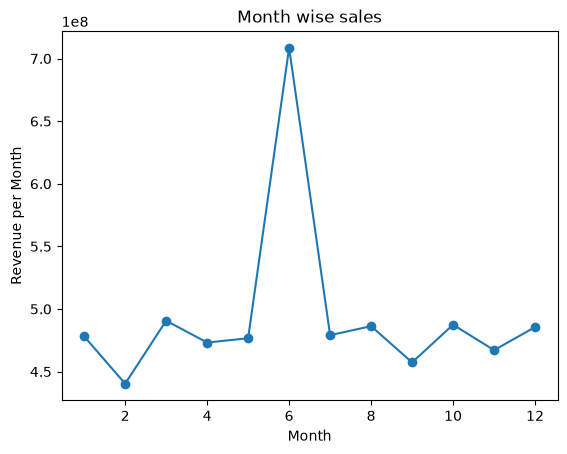

In [5]:
# Which months perform best
sales['Order_Date'] = pd.to_datetime(sales['Order_Date'])
monthly_sales = sales.groupby(sales['Order_Date'].dt.month)['Total_Amount'].sum()

monthly_sales.plot(kind='line', marker='o')
plt.title("Month wise sales")
plt.xlabel("Month")
plt.ylabel("Revenue per Month")
plt.show()

0    Delivered
Name: Order_Status, dtype: str


<Axes: xlabel='Order_Status'>

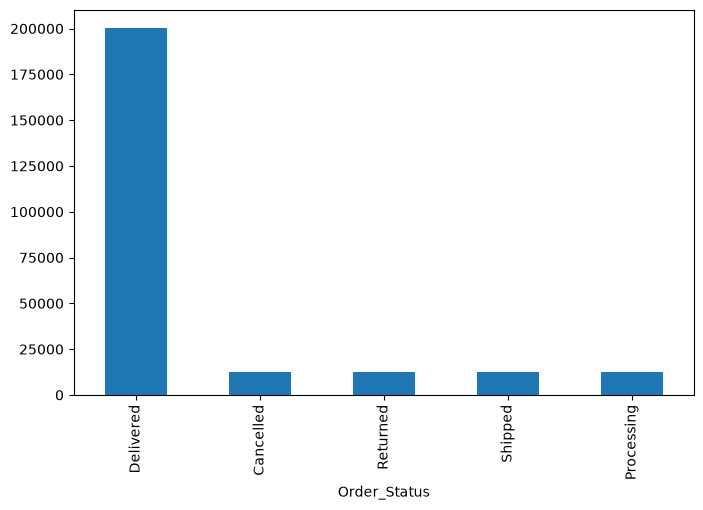

In [6]:
# Which order status is most common
print(sales['Order_Status'].mode())

sales['Order_Status'].value_counts().plot(kind='bar', figsize=(8, 5))

0    UPI
Name: Payment_Mode, dtype: str


<Axes: >

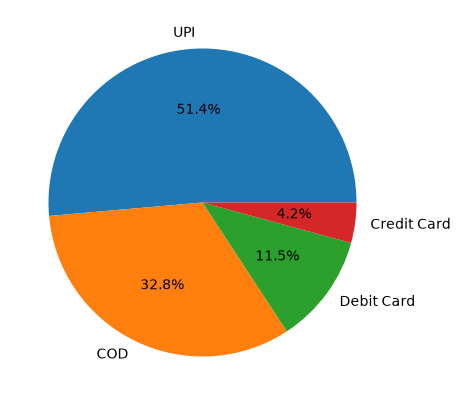

In [7]:
# Which payment methods are popular?
print(sales['Payment_Mode'].mode())

sales['Payment_Mode'].value_counts().plot(kind='pie', autopct='%1.1f%%',figsize=(8, 5))

## 3. Customer Analysis
Explore customer location, age, customer tier, and spending.

Questions:
- Which states have the most customers?
- Which customer tiers are common?
- What does the age distribution look like?
- Which customers spend the most?

<Axes: xlabel='State'>

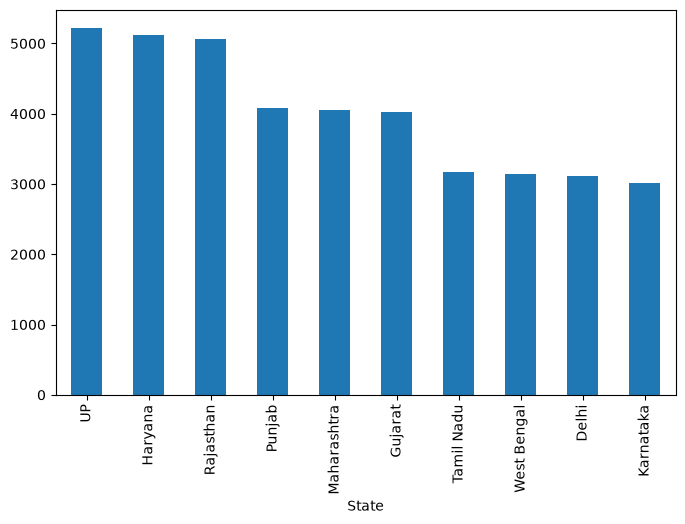

In [8]:
# Which states have the most customers?
customers['State'].value_counts().sort_values(ascending=False).plot(kind='bar', figsize=(8, 5))

<Axes: xlabel='Customer_Tier'>

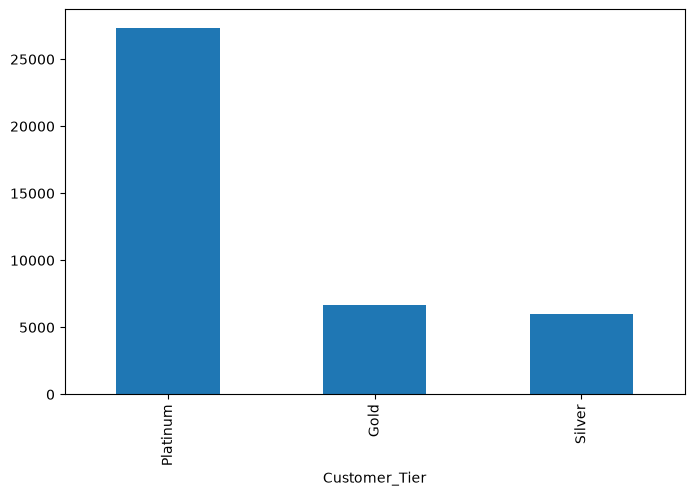

In [9]:
# Which customer tiers are most common?
customers['Customer_Tier'].value_counts().plot(kind='bar', figsize=(8, 5))

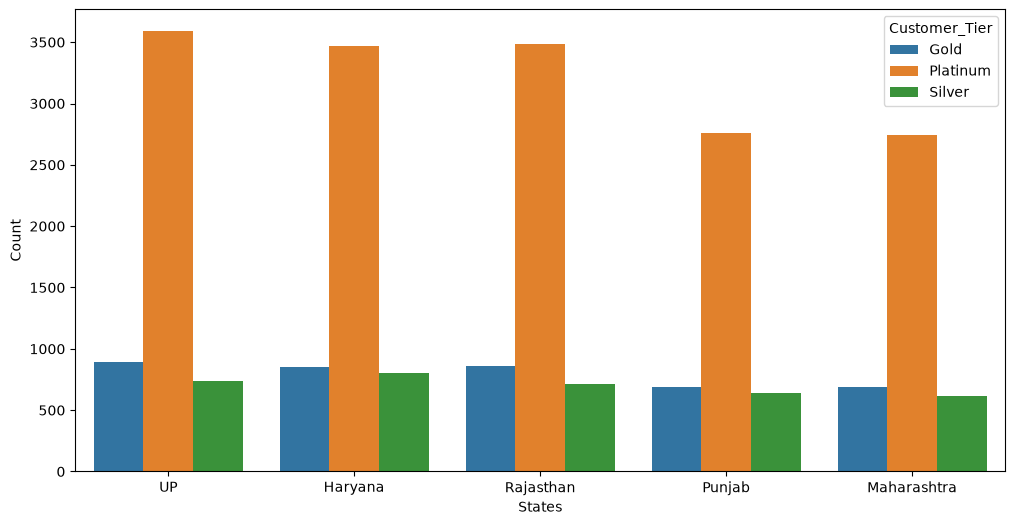

In [10]:
# Customer Tier with states
top_states = customers['State'].value_counts().sort_values(ascending=False).head(5).index


plt.figure(figsize=(12, 6))
sns.countplot(
    data=customers,
    x='State',
    hue='Customer_Tier',
    order=top_states,
)

plt.xlabel('States')
plt.ylabel('Count')
plt.show()

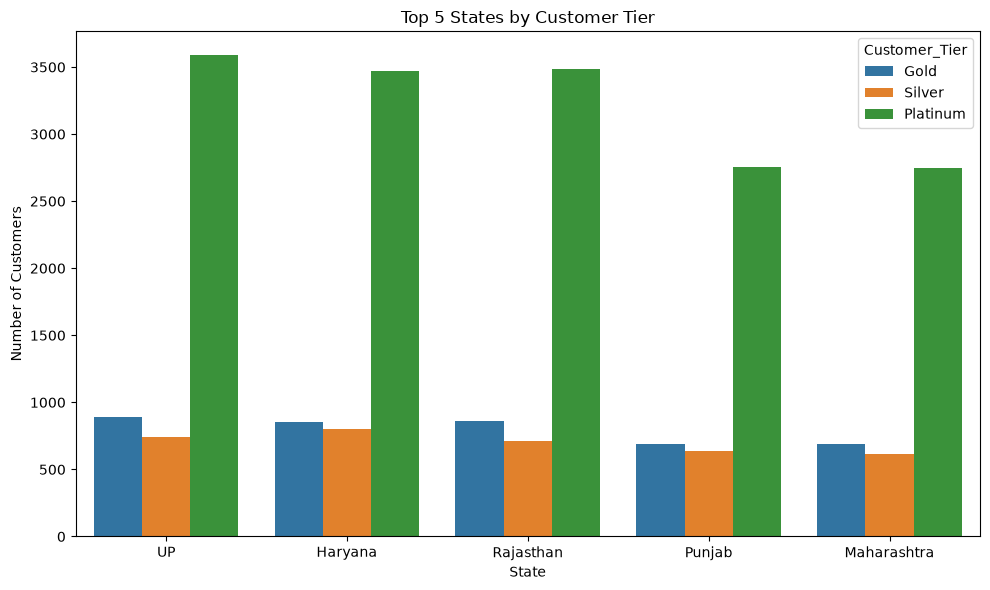

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

top_5_states = customers['State'].value_counts().head(5).index

top_data = customers[customers['State'].isin(top_5_states)]

plt.figure(figsize=(10, 6))

sns.countplot(
    data=top_data,
    x='State',
    hue='Customer_Tier',
    order=customers['State'].value_counts().head(5).index
)

plt.title('Top 5 States by Customer Tier')
plt.xlabel('State')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Product Analysis
Explore categories, brands, prices, ratings, and stock.

Questions:
- Which categories and brands are common?
- Which products generate the most sales value?
- Which products have the highest ratings?
- Are any products low in stock?

In [12]:
# Joining the sales and products tables to analyze product categories and brands
sales_products = pd.merge(sales, products, on='Product_ID', how='left')

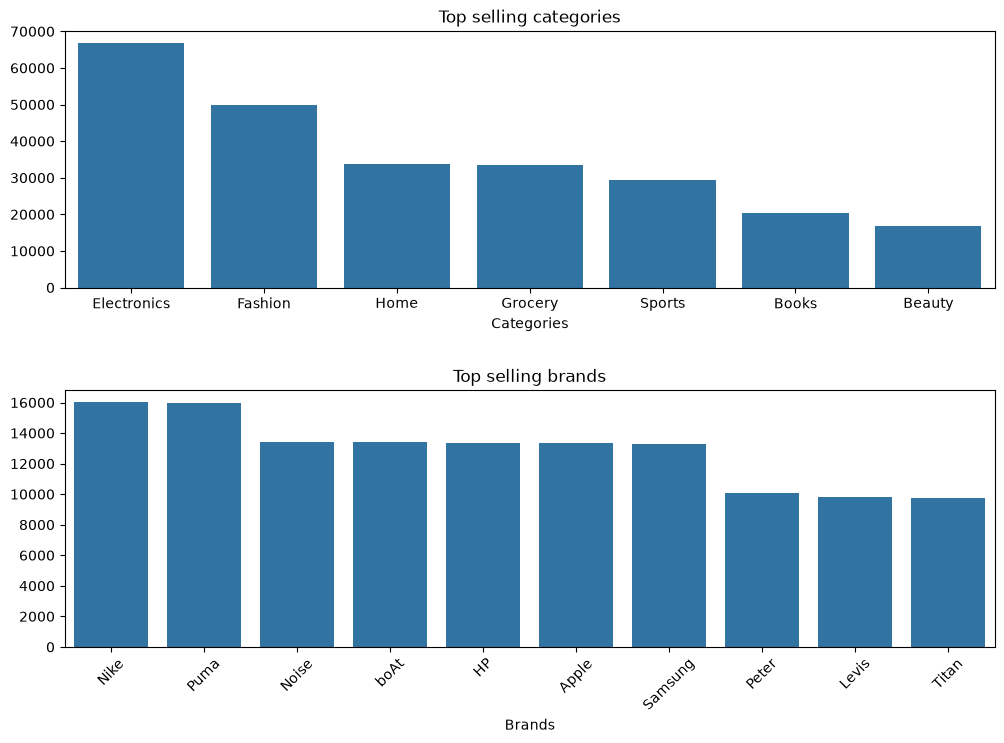

In [13]:
# Which categories and brands are common?
categories_count = sales_products['Category'].value_counts()
brand_count = sales_products['Brand'].value_counts().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(2, 1, figsize=(12, 8))
plt.subplot(2, 1, 1)
sns.barplot(x=categories_count.index, y=categories_count.values)
plt.title("Top selling categories")
plt.xlabel("Categories")

plt.subplot(2, 1, 2)
sns.barplot(x=brand_count.index, y=brand_count.values)
plt.title("Top selling brands")
plt.xlabel("Brands")
plt.xticks(rotation=45)



plt.subplots_adjust(hspace=0.4)
# plt.tight_layout()
plt.show()


Product_Name
Noise Watch V1       193,460,227.62
Samsung Mobile V4    174,666,662.18
boAt Headphones V8   158,780,018.54
HP Laptop V5         158,264,183.33
boAt Headphones V6   141,722,345.08
Noise Watch V7       141,229,928.62
Apple iPhone V7      135,870,838.30
HP Laptop V10        132,166,830.65
HP Laptop V4         125,116,650.71
boAt Headphones V2   119,326,117.43
Name: Total_Amount, dtype: float64


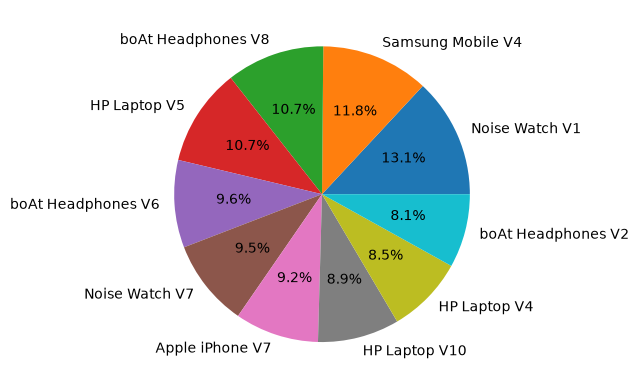

In [14]:
# Which product generate the most sales value?
products_name = sales_products.groupby(sales_products['Product_Name'])['Total_Amount'].sum()
pd.set_option('display.float_format', '{:,.2f}'.format)
top_product_ranking = products_name.sort_values(ascending=False).head(10)
print(top_product_ranking)

plt.pie(
    top_product_ranking,
    labels=top_product_ranking.index,
    autopct='%1.1f%%'
)

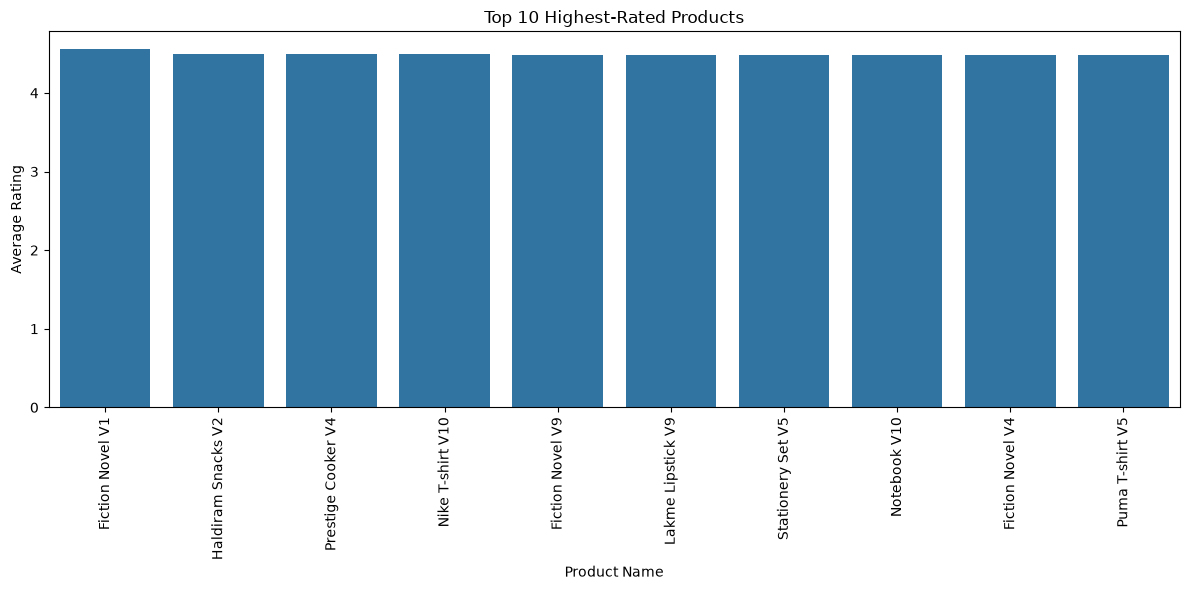

In [15]:
# Which product has highest rating
highest_rating = sales_products.groupby('Product_Name')['Rating'].mean().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    x=highest_rating.index,
    y=highest_rating.values,
)

ax.set_title("Top 10 Highest-Rated Products")
ax.set_xlabel("Product Name")
ax.set_ylabel("Average Rating")
ax.tick_params(axis='x', rotation=90)
fig.tight_layout()
plt.show()

In [16]:
# Are any product low in stock?
low_product_quntity = sales_products.groupby(sales_products['Product_Name'])['Stock_Quantity'].mean().sort_values().head(20)
low_product_quntity

Product_Name
Levis Jeans V6          138.45
Levis Jeans V9          160.53
Noise Watch V6          184.00
Lays Chips V3           191.00
Aashirvaad Atta V9      195.16
Lakme Lipstick V2       206.00
Titan Watch V4          246.54
Dumbbells V9            246.67
Puma Shoes V3           255.72
Urban Ladder Sofa V8    258.38
Fiction Novel V9        260.00
Stationery Set V6       264.95
Urban Ladder Sofa V2    265.64
Urban Ladder Sofa V10   265.72
Philips Mixer V8        273.84
Nike T-shirt V10        276.00
Puma T-shirt V9         282.87
Fiction Novel V4        289.40
NCERT Book V2           291.54
Urban Ladder Sofa V7    292.54
Name: Stock_Quantity, dtype: float64

## 5. Combined Analysis
Join tables only when needed for a question.

Questions:
- Which states generate the most sales value?
- Do order statuses differ by category?
- How do discounts relate to sales value?

<Axes: xlabel='State'>

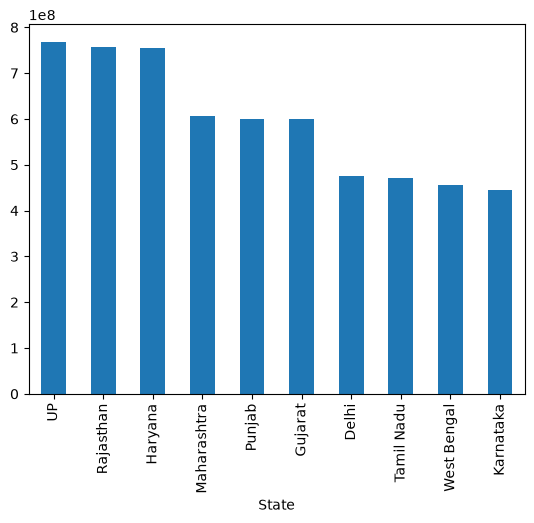

In [17]:
# Which states generate the most sales values?
sales_by_state = sales.groupby(sales['State'])['Total_Amount'].sum().sort_values(ascending=False)
sales_by_state.plot(kind='bar')

In [18]:
# Do Order statuses differ by category?




Correation between discount and total sales:
0.23859854955769333


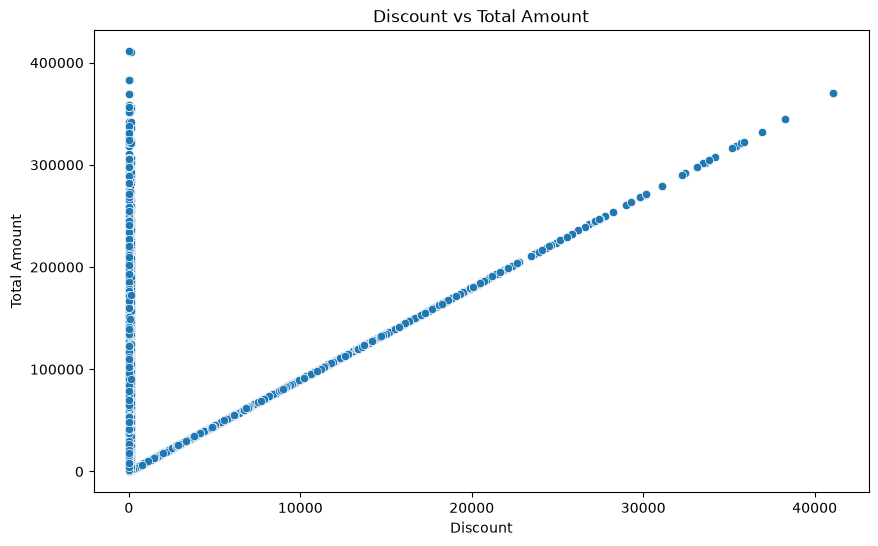

In [19]:
# How does discount related sales?
print("Correation between discount and total sales:")
print(sales_products['Coupon_Discount'].corr(sales_products['Total_Amount']))

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=sales_products,
    x = 'Coupon_Discount',
    y = 'Total_Amount'
)
ax.set_title("Discount vs Total Amount")
ax.set_xlabel("Discount")
ax.set_ylabel("Total Amount")
plt.show()

## 6. Visualizations
Create a few clear charts for the most useful findings:
- Monthly sales trend
- Order status count
- Customers by state
- Sales value by customer tier

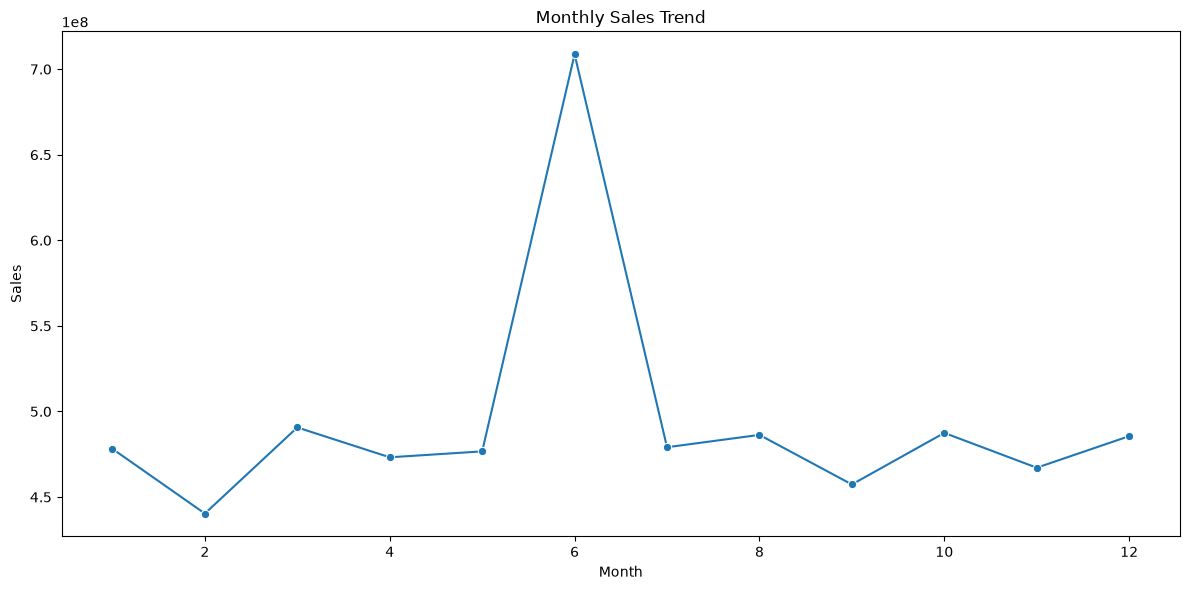

In [20]:
# Monthly sales trend
fig, ax = plt.subplots(figsize=(12, 6))

# monthly_sales.plot(kind='line', markers='o')
sns.lineplot(
    x = monthly_sales.index,
    y = monthly_sales.values,
    marker='o',
    ax = ax
)
ax.set_title('Monthly Sales Trend')
ax.set_xlabel('Month')
ax.set_ylabel('Sales')

fig.tight_layout()
plt.show()

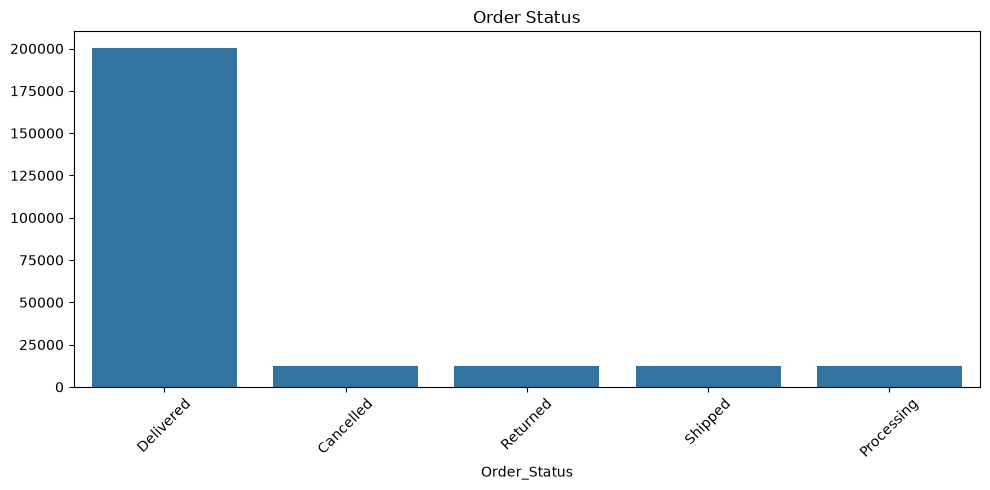

In [26]:
# Order Status count
order_status = sales['Order_Status'].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    x = order_status.index,
    y = order_status.values
)
ax.set_title('Order Status')
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

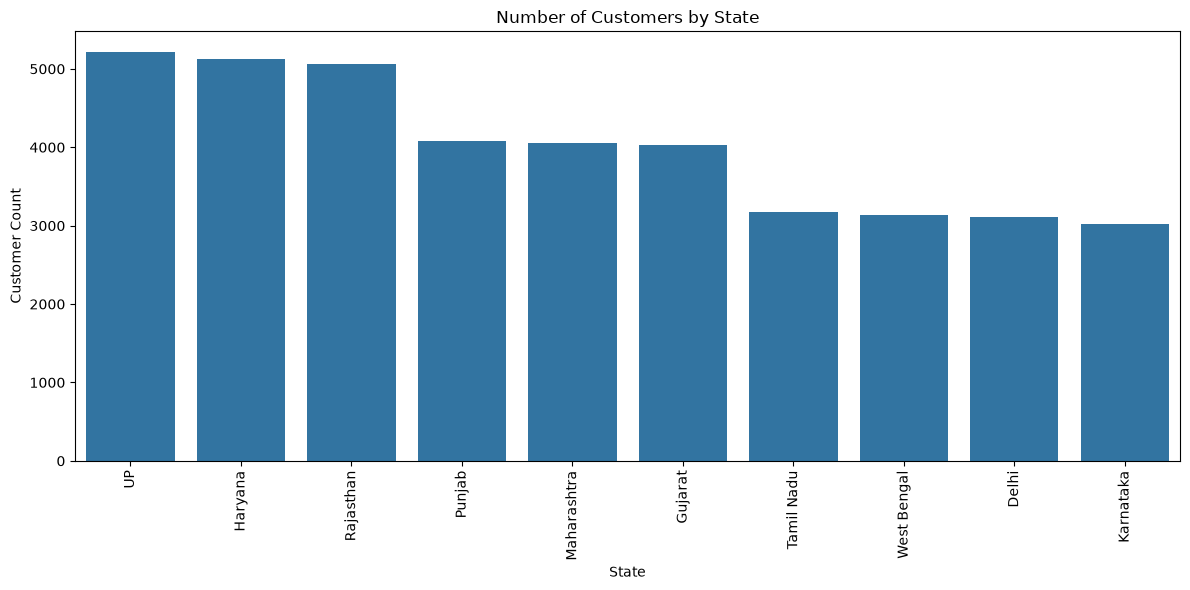

In [29]:
# Customer by state
state_count = customers['State'].value_counts()

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    x=state_count.index,
    y=state_count.values,
    ax=ax
)

ax.set_title('Number of Customers by State')
ax.set_xlabel('State')
ax.set_ylabel('Customer Count')
ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

<Axes: xlabel='Customer_Tier'>

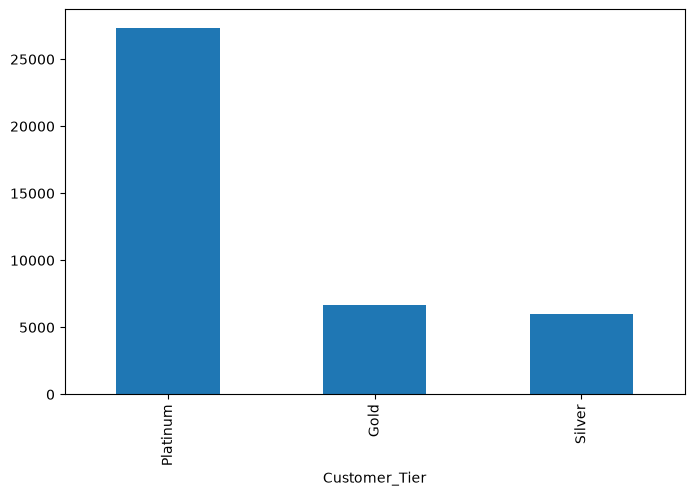

In [30]:
customers['Customer_Tier'].value_counts().plot(kind='bar', figsize=(8, 5))

## 7. Findings
Write 5–8 observations in your own words.

For each finding, note the result and why it may matter to the business.

## Next Step
SQL business analysis